In [1]:

!pip install gymnasium numpy matplotlib imageio pillow


In [3]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import imageio.v2 as imageio
import os

# Create the environment
env = gym.make(
    "FrozenLake-v1",
    is_slippery=False,
    render_mode="rgb_array"
)

# Get number of states and actions
n_states = env.observation_space.n
n_actions = env.action_space.n

print("Environment: FrozenLake-v1")
print("Number of states:", n_states)
print("Number of actions:", n_actions)
print("Actions: 0=Left, 1=Down, 2=Right, 3=Up")


Environment: FrozenLake-v1
Number of states: 16
Number of actions: 4
Actions: 0=Left, 1=Down, 2=Right, 3=Up


Implement Q-Learning

In [4]:

# Step 4: Q-Learning Algorithm

# Hyperparameters
learning_rate = 0.8
discount_factor = 0.95
epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.9995

episodes = 15000
max_steps = 100

# Initialize Q-table with zeros
Q = np.zeros((n_states, n_actions))

# Store rewards and success for analysis
rewards_per_episode = []
success_per_episode = []

# Training loop
for episode in range(episodes):
    state, info = env.reset()
    total_reward = 0

    for step in range(max_steps):

        # Explore or choose the best action
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = int(np.argmax(Q[state]))

        # Perform the action
        next_state, reward, terminated, truncated, info = (
            env.step(action)
        )

        # Update Q-value
        best_next_value = np.max(Q[next_state])

        target = reward + discount_factor * best_next_value

        Q[state, action] += learning_rate * (
            target - Q[state, action]
        )

        # Move to the next state
        state = next_state
        total_reward += reward

        if terminated or truncated:
            break

    rewards_per_episode.append(total_reward)
    success_per_episode.append(int(total_reward > 0))

    # Reduce exploration gradually
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Training completed!")
print("Q-table shape:", Q.shape)
print("Final epsilon:", round(epsilon, 4))
print("Total episodes:", episodes)


Training completed!
Q-table shape: (16, 4)
Final epsilon: 0.01
Total episodes: 15000


Test the agent's success rate

In [5]:

# Step 5: Evaluate the trained agent

test_episodes = 100
successful_episodes = 0

for episode in range(test_episodes):
    state, info = env.reset()

    for step in range(max_steps):
        # Select the best learned action
        action = int(np.argmax(Q[state]))

        # Take the action
        state, reward, terminated, truncated, info = (
            env.step(action)
        )

        # Stop when the episode ends
        if terminated or truncated:
            if reward == 1:
                successful_episodes += 1
            break

# Calculate success rate
success_rate = (
    successful_episodes / test_episodes
) * 100

print("Evaluation completed!")
print("Successful episodes:", successful_episodes)
print("Total test episodes:", test_episodes)
print(f"Success rate: {success_rate:.2f}%")


Evaluation completed!
Successful episodes: 100
Total test episodes: 100
Success rate: 100.00%


Create the training graph

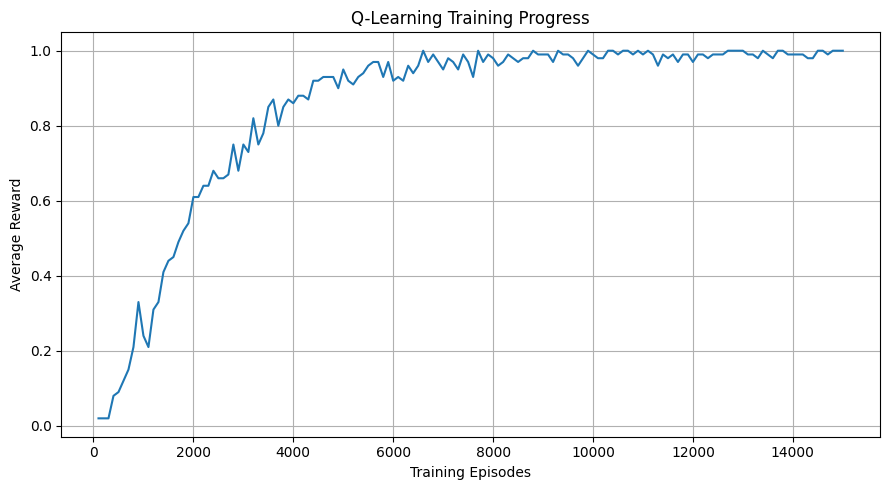

Training graph saved successfully!


In [6]:

# Step 6: Plot Training Progress

block_size = 100

rewards = np.array(rewards_per_episode)

# Calculate average reward for every 100 episodes
trimmed_length = (
    len(rewards) // block_size
) * block_size

trimmed_rewards = rewards[:trimmed_length]

average_rewards = trimmed_rewards.reshape(
    -1, block_size
).mean(axis=1)

# Plot graph
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(average_rewards) + 1) * block_size,
    average_rewards
)

plt.xlabel("Training Episodes")
plt.ylabel("Average Reward")
plt.title("Q-Learning Training Progress")
plt.grid(True)

plt.tight_layout()
plt.savefig("training_progress.png", dpi=150)
plt.show()

print("Training graph saved successfully!")


Visualize the learned Q-table

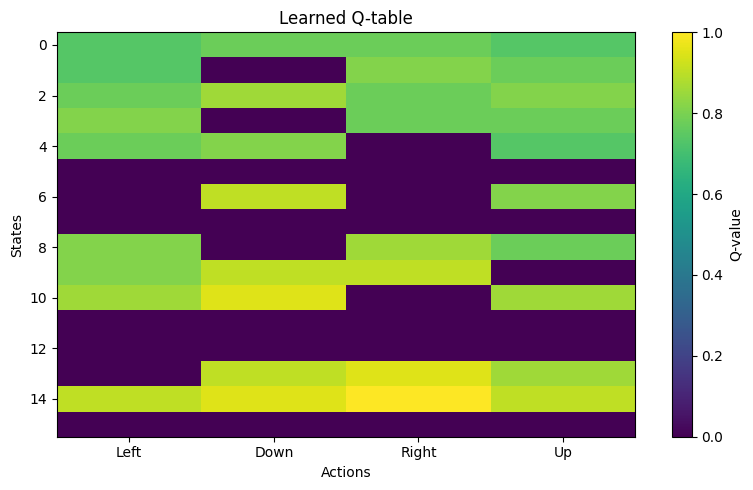

Q-table visualization saved successfully!


In [7]:

# Step 7: Visualize the Q-table

plt.figure(figsize=(8, 5))

plt.imshow(Q, aspect="auto")
plt.colorbar(label="Q-value")

plt.xlabel("Actions")
plt.ylabel("States")
plt.title("Learned Q-table")

plt.xticks(
    range(n_actions),
    ["Left", "Down", "Right", "Up"]
)

plt.tight_layout()
plt.savefig("q_table.png", dpi=150)
plt.show()

print("Q-table visualization saved successfully!")


Save your trained Q-table

In [8]:

# Step 8: Save the trained Q-table

np.save("q_table.npy", Q)

print("Q-table saved successfully!")

# Verify the saved file
loaded_Q = np.load("q_table.npy")

print("Q-table shape:", loaded_Q.shape)
print("File loaded successfully:", np.array_equal(Q, loaded_Q))


Q-table saved successfully!
Q-table shape: (16, 4)
File loaded successfully: True


Create a GIF of the trained agent

In [9]:

# Step 9: Record the trained agent

frames = []

state, info = env.reset()
frames.append(env.render())

total_reward = 0

for step in range(max_steps):
    # Choose the best action from the learned Q-table
    action = int(np.argmax(Q[state]))

    state, reward, terminated, truncated, info = (
        env.step(action)
    )

    total_reward += reward
    frames.append(env.render())

    if terminated or truncated:
        break

# Save the GIF
imageio.mimsave(
    "trained_agent.gif",
    frames,
    duration=500,
    loop=0
)

print("GIF saved successfully!")
print("Reached goal:", total_reward > 0)
print("File: trained_agent.gif")


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


GIF saved successfully!
Reached goal: True
File: trained_agent.gif


In [10]:

%%writefile agent.py
import numpy as np


class QLearningAgent:
    def __init__(
        self,
        n_states,
        n_actions,
        learning_rate=0.8,
        discount_factor=0.95
    ):
        self.q_table = np.zeros((n_states, n_actions))
        self.lr = learning_rate
        self.gamma = discount_factor

    def choose_action(self, state, epsilon, action_space):
        if np.random.random() < epsilon:
            return action_space.sample()

        return int(np.argmax(self.q_table[state]))

    def learn(
        self, state, action, reward,
        next_state, terminated
    ):
        if terminated:
            future_reward = 0
        else:
            future_reward = (
                self.gamma * np.max(self.q_table[next_state])
            )

        target = reward + future_reward

        self.q_table[state, action] += self.lr * (
            target - self.q_table[state, action]
        )


Writing agent.py


In [11]:

%%writefile utils.py
import numpy as np


def evaluate_agent(env, q_table, episodes=100):
    successes = 0

    for _ in range(episodes):
        state, info = env.reset()

        for _ in range(100):
            action = int(np.argmax(q_table[state]))

            state, reward, terminated, truncated, info = (
                env.step(action)
            )

            if terminated or truncated:
                if reward == 1:
                    successes += 1
                break

    return (successes / episodes) * 100


Writing utils.py


In [12]:

%%writefile main.py
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

from agent import QLearningAgent
from utils import evaluate_agent


def main():
    # Create the environment
    env = gym.make(
        "FrozenLake-v1",
        is_slippery=False
    )

    # Initialize the agent
    agent = QLearningAgent(
        env.observation_space.n,
        env.action_space.n,
        learning_rate=0.8,
        discount_factor=0.95
    )

    episodes = 15000
    epsilon = 1.0
    epsilon_min = 0.01
    epsilon_decay = 0.9995
    rewards = []

    # Train the agent
    for episode in range(episodes):
        state, info = env.reset()
        total_reward = 0

        for step in range(100):
            action = agent.choose_action(
                state, epsilon, env.action_space
            )

            next_state, reward, terminated, truncated, info = (
                env.step(action)
            )

            agent.learn(
                state, action, reward,
                next_state, terminated
            )

            state = next_state
            total_reward += reward

            if terminated or truncated:
                break

        rewards.append(total_reward)
        epsilon = max(
            epsilon_min, epsilon * epsilon_decay
        )

    # Save trained model
    np.save("q_table.npy", agent.q_table)

    # Evaluate the agent
    success_rate = evaluate_agent(
        env, agent.q_table, episodes=100
    )

    print("Training completed!")
    print(f"Test success rate: {success_rate:.2f}%")

    # Plot training progress
    block_size = 100
    values = np.array(rewards)
    averages = values.reshape(-1, block_size).mean(axis=1)

    plt.figure(figsize=(8, 4))
    plt.plot(
        np.arange(1, len(averages) + 1) * block_size,
        averages
    )
    plt.xlabel("Training Episodes")
    plt.ylabel("Average Reward")
    plt.title("Q-Learning Training Progress")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("training_progress.png", dpi=150)
    plt.show()

    env.close()


if __name__ == "__main__":
    main()


Writing main.py


In [13]:

%%writefile requirements.txt
gymnasium
numpy
matplotlib
imageio
pillow


Writing requirements.txt


In [14]:

!python main.py


Training completed!
Test success rate: 100.00%
Figure(800x400)
